# 06 — Toronto thermal walking network (corrected sampling)

## Purpose

This notebook transfers the **observed-event common-time UTCI field**
from Notebook 05 onto the Toronto walking network.

This version corrects an important sampling issue discovered in the first run:
some edge samples were taken outside the raster extent, which produced impossible
edge-level UTCI values below the raster minimum.

The corrected workflow:

1. loads the Toronto 8×8 km walking graph;
2. loads `utci_2025-07-25_1500.tif`;
3. projects the graph to the raster CRS;
4. clips the network to the thermal raster footprint;
5. retains only edges fully covered by the raster;
6. samples UTCI along each edge using only coordinates inside raster bounds;
7. validates that edge UTCI remains within the raster UTCI range;
8. computes walking time and thermal cost;
9. quantifies edge-level thermal heterogeneity;
10. saves the corrected thermal graph for accessibility analysis.

Thermal generalized cost:

\[
c_e^{heat}
=
t_e
\left[
1 + \lambda \max(UTCI_e - 32, 0)
ight]
\]

with λ treated as a **sensitivity parameter**, not a calibrated behavior coefficient.

**Kernel:** Python 3.12 - VoxCity

## 1. Imports and project paths

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import osmnx as ox
import pandas as pd
import rasterio

from shapely.geometry import box

HERE = Path.cwd().resolve()

if HERE.name == "notebooks_toronto_v02":
    PROJECT_ROOT = HERE.parent
elif (HERE / "notebooks_toronto_v02").exists():
    PROJECT_ROOT = HERE
else:
    PROJECT_ROOT = Path(
        "/scratch/project_2010417/paper3/heat-conditioned-accessibility"
    )

TORONTO_DATA = PROJECT_ROOT / "data" / "toronto"
TORONTO_RAW = TORONTO_DATA / "raw"
TORONTO_INTERIM = TORONTO_DATA / "interim"
TORONTO_OUTPUTS = PROJECT_ROOT / "outputs" / "toronto"

WALK_GRAPH_PATH = (
    TORONTO_RAW
    / "toronto_walk_8km.graphml"
)

UTCI_PATH = (
    TORONTO_OUTPUTS
    / "solweig"
    / "UOFT_PILOT_2025-07-25_1500"
    / "utci_2025-07-25_1500.tif"
)

THERMAL_NETWORK_DIR = (
    TORONTO_INTERIM
    / "thermal_network"
)

THERMAL_NETWORK_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print("Walking graph:", WALK_GRAPH_PATH)
print("UTCI raster:", UTCI_PATH)

Walking graph: /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/raw/toronto_walk_8km.graphml
UTCI raster: /scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/toronto/solweig/UOFT_PILOT_2025-07-25_1500/utci_2025-07-25_1500.tif


## 2. Load the full Toronto walking graph

In [2]:
if not WALK_GRAPH_PATH.exists():
    raise FileNotFoundError(
        f"Walking graph not found: {WALK_GRAPH_PATH}"
    )

G = ox.load_graphml(
    WALK_GRAPH_PATH
)

print("Full graph nodes:", G.number_of_nodes())
print("Full graph edges:", G.number_of_edges())
print("Graph CRS:", G.graph.get("crs"))

Full graph nodes: 35817
Full graph edges: 96924
Graph CRS: EPSG:32617


## 3. Load the observed-event UTCI raster

The thermal raster represents:

**25 July 2025 at 15:00 Toronto local time**

In [3]:
if not UTCI_PATH.exists():
    raise FileNotFoundError(
        f"Observed-event UTCI raster not found: {UTCI_PATH}"
    )

with rasterio.open(
    UTCI_PATH
) as src:

    utci = src.read(1).astype(
        np.float32
    )

    utci_crs = src.crs
    utci_transform = src.transform
    utci_bounds = src.bounds
    utci_nodata = src.nodata

raster_min = float(
    np.nanmin(utci)
)

raster_mean = float(
    np.nanmean(utci)
)

raster_max = float(
    np.nanmax(utci)
)

raster_sd = float(
    np.nanstd(utci)
)

print("UTCI CRS:", utci_crs)
print("UTCI shape:", utci.shape)
print("UTCI bounds:", utci_bounds)

print()
print("Raster UTCI min :", raster_min)
print("Raster UTCI mean:", raster_mean)
print("Raster UTCI max :", raster_max)
print("Raster UTCI SD  :", raster_sd)

UTCI CRS: EPSG:32617
UTCI shape: (416, 416)
UTCI bounds: BoundingBox(left=628285.2587542166, bottom=4834731.633532561, right=630365.2587542166, top=4836811.633532561)

Raster UTCI min : 29.449005126953125
Raster UTCI mean: 35.70380783081055
Raster UTCI max : 36.364173889160156
Raster UTCI SD  : 0.6367783546447754


## 4. Project the walking graph to the UTCI raster CRS

In [4]:
G_proj = ox.project_graph(
    G,
    to_crs=utci_crs,
)

nodes_proj, edges_proj = (
    ox.graph_to_gdfs(
        G_proj
    )
)

print(
    "Projected graph CRS:",
    nodes_proj.crs,
)

Projected graph CRS: PROJCS["WGS 84 / UTM zone 17N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-81],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32617"]]


## 5. Define the exact thermal raster footprint

The raster bounds are converted into a polygon.

Only edges fully covered by this footprint are retained for thermal sampling.

In [5]:
thermal_polygon = box(
    utci_bounds.left,
    utci_bounds.bottom,
    utci_bounds.right,
    utci_bounds.top,
)

thermal_extent = gpd.GeoDataFrame(
    {
        "name": [
            "UOFT_PILOT_thermal_extent"
        ],
    },
    geometry=[
        thermal_polygon
    ],
    crs=utci_crs,
)

print(
    "Thermal footprint area (km²):",
    thermal_extent.geometry.area.iloc[0]
    / 1_000_000,
)

Thermal footprint area (km²): 4.3264


## 6. Retain graph nodes inside the thermal footprint

In [6]:
nodes_inside = nodes_proj[
    nodes_proj.geometry.within(
        thermal_polygon
    )
    |
    nodes_proj.geometry.touches(
        thermal_polygon
    )
].copy()

node_ids_inside = set(
    nodes_inside.index
)

print(
    "Nodes inside thermal footprint:",
    len(node_ids_inside),
)

Nodes inside thermal footprint: 3996


## 7. Build the initial thermal subgraph

In [7]:
G_thermal = (
    G_proj
    .subgraph(
        node_ids_inside
    )
    .copy()
)

print(
    "Initial thermal subgraph nodes:",
    G_thermal.number_of_nodes(),
)

print(
    "Initial thermal subgraph edges:",
    G_thermal.number_of_edges(),
)

Initial thermal subgraph nodes: 3996
Initial thermal subgraph edges: 10684


## 8. Keep the largest weakly connected component

In [8]:
components = sorted(
    nx.weakly_connected_components(
        G_thermal
    ),
    key=len,
    reverse=True,
)

if not components:
    raise RuntimeError(
        "No connected components found in thermal subgraph."
    )

G_thermal = (
    G_thermal
    .subgraph(
        components[0]
    )
    .copy()
)

print(
    "Largest weak component nodes:",
    G_thermal.number_of_nodes(),
)

print(
    "Largest weak component edges:",
    G_thermal.number_of_edges(),
)

Largest weak component nodes: 3886
Largest weak component edges: 10558


## 9. Keep only edges fully covered by the raster

This is the key correction.

Edges that merely touch or cross the thermal boundary can otherwise generate
sample points outside the raster. Those out-of-bounds samples caused impossible
edge-level UTCI values in the first version.

In [9]:
thermal_nodes, thermal_edges = (
    ox.graph_to_gdfs(
        G_thermal
    )
)

fully_covered_mask = (
    thermal_edges.geometry.covered_by(
        thermal_polygon
    )
)

thermal_edges = (
    thermal_edges[
        fully_covered_mask
    ]
    .copy()
)

print(
    "Edges before full-coverage filter:",
    len(
        ox.graph_to_gdfs(
            G_thermal
        )[1]
    ),
)

print(
    "Edges fully covered by UTCI raster:",
    len(
        thermal_edges
    ),
)

Edges before full-coverage filter: 10558
Edges fully covered by UTCI raster: 10556


## 10. Visualize the retained thermal network

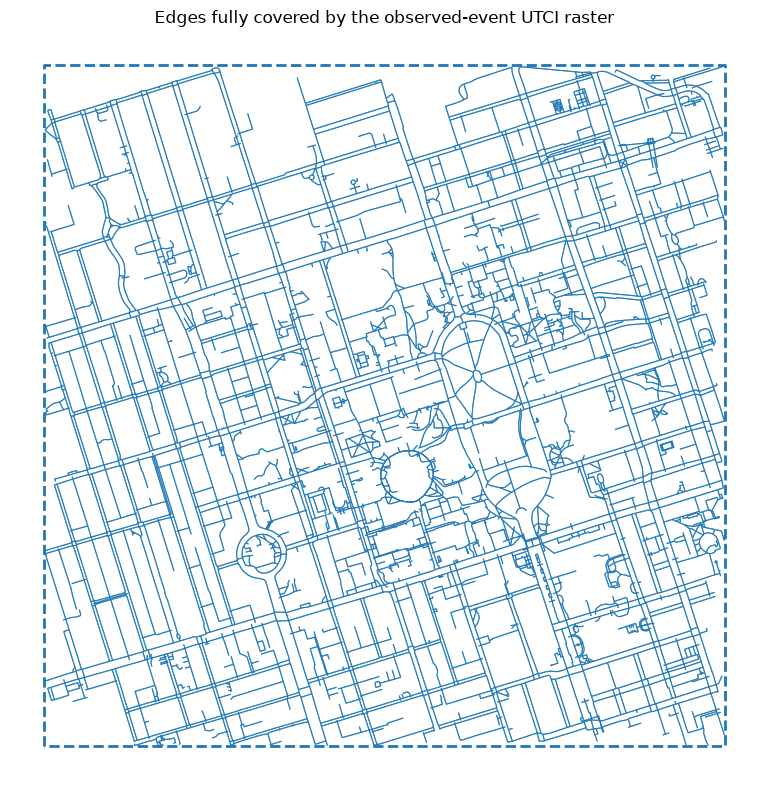

In [10]:
fig, ax = plt.subplots(
    figsize=(8, 8)
)

thermal_extent.boundary.plot(
    ax=ax,
    linewidth=2.0,
    linestyle="--",
)

thermal_edges.plot(
    ax=ax,
    linewidth=0.8,
    alpha=0.8,
)

ax.set_title(
    "Edges fully covered by the observed-event UTCI raster"
)

ax.set_axis_off()

plt.tight_layout()
plt.show()

## 11. Define edge-sampling settings

UTCI is sampled at multiple points along each edge.

- target spacing: **10 m**
- minimum samples per edge: **3**

In [11]:
EDGE_SAMPLE_SPACING_M = 10.0
MIN_EDGE_SAMPLES = 3

print(
    "Target spacing:",
    EDGE_SAMPLE_SPACING_M,
    "m",
)

print(
    "Minimum samples:",
    MIN_EDGE_SAMPLES,
)

Target spacing: 10.0 m
Minimum samples: 3


In [12]:
def sample_points_along_line(
    geometry,
    spacing=10.0,
    min_samples=3,
):

    length = float(
        geometry.length
    )

    if length <= 0:

        return [
            geometry.centroid
        ]

    n_samples = max(
        min_samples,
        int(
            np.ceil(
                length / spacing
            )
        ) + 1,
    )

    distances = np.linspace(
        0,
        length,
        n_samples,
    )

    return [
        geometry.interpolate(
            distance
        )
        for distance in distances
    ]

## 12. Sample UTCI along each edge with explicit raster-bound checks

Even though fully covered edges are retained, every sample coordinate is still
checked against raster bounds before calling `src.sample()`.

In [13]:
with rasterio.open(
    UTCI_PATH
) as src:

    bounds = src.bounds

    edge_utci = []
    edge_sample_count = []

    for idx, row in thermal_edges.iterrows():

        geometry = row.geometry

        points = sample_points_along_line(
            geometry,
            spacing=EDGE_SAMPLE_SPACING_M,
            min_samples=MIN_EDGE_SAMPLES,
        )

        coords = [
            (
                point.x,
                point.y,
            )
            for point in points
            if (
                bounds.left
                <= point.x
                < bounds.right
                and
                bounds.bottom
                < point.y
                <= bounds.top
            )
        ]

        if len(coords) == 0:

            edge_utci.append(
                np.nan
            )

            edge_sample_count.append(
                0
            )

            continue

        sampled_values = np.array(
            [
                value[0]
                for value
                in src.sample(
                    coords
                )
            ],
            dtype=float,
        )

        valid = np.isfinite(
            sampled_values
        )

        if src.nodata is not None:

            valid &= (
                sampled_values
                != src.nodata
            )

        sampled_values = (
            sampled_values[
                valid
            ]
        )

        if len(
            sampled_values
        ) == 0:

            edge_utci.append(
                np.nan
            )

            edge_sample_count.append(
                0
            )

        else:

            edge_utci.append(
                float(
                    np.mean(
                        sampled_values
                    )
                )
            )

            edge_sample_count.append(
                int(
                    len(
                        sampled_values
                    )
                )
            )

thermal_edges[
    "utci_1500"
] = edge_utci

thermal_edges[
    "utci_sample_n"
] = edge_sample_count

display(
    thermal_edges[
        [
            "length",
            "utci_1500",
            "utci_sample_n",
        ]
    ].describe()
)

,length,utci_1500,utci_sample_n
count,10556.000000,10556.000000,10556.000000
mean,31.967763,35.576699,4.984085
std,37.622891,0.616346,3.592209
min,0.125179,30.965675,3.000000
25%,9.293289,35.496085,3.000000
50%,18.382359,35.790959,3.000000
75%,41.801727,35.935836,6.000000
max,372.304178,36.287238,39.000000


## 13. Validate edge UTCI against the raster range

This assertion is essential.

An edge mean should never fall outside the range of the raster values from which
it was sampled.

In [14]:
edge_min = float(
    thermal_edges[
        "utci_1500"
    ].min()
)

edge_max = float(
    thermal_edges[
        "utci_1500"
    ].max()
)

print(
    "Raster UTCI range:",
    raster_min,
    "to",
    raster_max,
)

print(
    "Edge UTCI range:",
    edge_min,
    "to",
    edge_max,
)

tolerance = 0.01

assert (
    edge_min
    >= raster_min
    - tolerance
), (
    "Edge UTCI minimum is below raster minimum."
)

assert (
    edge_max
    <= raster_max
    + tolerance
), (
    "Edge UTCI maximum is above raster maximum."
)

print(
    "✓ Edge samples are within the raster UTCI range."
)

Raster UTCI range: 29.449005126953125 to 36.364173889160156
Edge UTCI range: 30.965675354003906 to 36.287237803141274
✓ Edge samples are within the raster UTCI range.


## 14. Inspect missing thermal samples

In [15]:
n_edges = len(
    thermal_edges
)

n_missing = int(
    thermal_edges[
        "utci_1500"
    ].isna().sum()
)

print(
    "Edges after coverage filter:",
    n_edges,
)

print(
    "Edges missing UTCI:",
    n_missing,
)

print(
    "Missing share:",
    round(
        100
        * n_missing
        / n_edges,
        3,
    ),
    "%",
)

Edges after coverage filter: 10556
Edges missing UTCI: 0
Missing share: 0.0 %


## 15. Retain edges with valid UTCI

In [16]:
thermal_edges_valid = (
    thermal_edges[
        thermal_edges[
            "utci_1500"
        ].notna()
    ]
    .copy()
)

print(
    "Valid thermal edges:",
    len(
        thermal_edges_valid
    ),
)

Valid thermal edges: 10556


## 16. Rebuild the corrected thermal graph

We rebuild a MultiDiGraph using only valid, fully covered thermal edges.

In [17]:
G_valid = nx.MultiDiGraph()

G_valid.graph.update(
    G_thermal.graph
)

valid_nodes = set()

for (
    u,
    v,
    key,
), row in thermal_edges_valid.iterrows():

    valid_nodes.add(u)
    valid_nodes.add(v)

for node_id in valid_nodes:

    G_valid.add_node(
        node_id,
        **G_thermal.nodes[
            node_id
        ],
    )

for (
    u,
    v,
    key,
), row in thermal_edges_valid.iterrows():

    attrs = row.drop(
        labels=[
            "geometry",
        ],
        errors="ignore",
    ).to_dict()

    attrs[
        "geometry"
    ] = row.geometry

    G_valid.add_edge(
        u,
        v,
        key=key,
        **attrs,
    )

print(
    "Rebuilt valid graph nodes:",
    G_valid.number_of_nodes(),
)

print(
    "Rebuilt valid graph edges:",
    G_valid.number_of_edges(),
)

Rebuilt valid graph nodes: 3886
Rebuilt valid graph edges: 10556


## 17. Keep the largest weakly connected corrected component

In [18]:
valid_components = sorted(
    nx.weakly_connected_components(
        G_valid
    ),
    key=len,
    reverse=True,
)

if not valid_components:
    raise RuntimeError(
        "No valid connected component remains."
    )

G_main = (
    G_valid
    .subgraph(
        valid_components[0]
    )
    .copy()
)

print(
    "Final corrected thermal graph nodes:",
    G_main.number_of_nodes(),
)

print(
    "Final corrected thermal graph edges:",
    G_main.number_of_edges(),
)

Final corrected thermal graph nodes: 3886
Final corrected thermal graph edges: 10556


## 18. Add walking time

Walking speed is fixed at **1.4 m/s** for comparability with Sevilla.

In [19]:
WALK_SPEED_MS = 1.4

for u, v, key, data in (
    G_main.edges(
        keys=True,
        data=True,
    )
):

    length_m = float(
        data.get(
            "length",
            0.0,
        )
    )

    data[
        "walk_time_s"
    ] = (
        length_m
        / WALK_SPEED_MS
    )

print(
    "Walking speed:",
    WALK_SPEED_MS,
    "m/s",
)

Walking speed: 1.4 m/s


## 19. Add heat excess above 32°C

In [20]:
HEAT_THRESHOLD_C = 32.0

for (
    u,
    v,
    key,
    data,
) in G_main.edges(
    keys=True,
    data=True,
):

    utci_value = float(
        data[
            "utci_1500"
        ]
    )

    data[
        "heat_excess"
    ] = max(
        utci_value
        - HEAT_THRESHOLD_C,
        0.0,
    )

print(
    "Heat threshold:",
    HEAT_THRESHOLD_C,
    "°C",
)

Heat threshold: 32.0 °C


## 20. Add reference thermal cost for λ = 0.05

In [21]:
REFERENCE_LAMBDA = 0.05

for (
    u,
    v,
    key,
    data,
) in G_main.edges(
    keys=True,
    data=True,
):

    walk_time = float(
        data[
            "walk_time_s"
        ]
    )

    heat_excess = float(
        data[
            "heat_excess"
        ]
    )

    thermal_cost = (
        walk_time
        * (
            1.0
            + REFERENCE_LAMBDA
            * heat_excess
        )
    )

    data[
        "thermal_cost_s"
    ] = thermal_cost

    data[
        "cost_ratio"
    ] = (
        thermal_cost
        / walk_time
        if walk_time > 0
        else np.nan
    )

## 21. Convert the final graph to GeoDataFrames

In [22]:
final_nodes, final_edges = (
    ox.graph_to_gdfs(
        G_main
    )
)

display(
    final_edges[
        [
            "length",
            "walk_time_s",
            "utci_1500",
            "heat_excess",
            "thermal_cost_s",
            "cost_ratio",
        ]
    ].describe()
)

,length,walk_time_s,utci_1500,heat_excess,thermal_cost_s,cost_ratio
count,10556.000000,10556.000000,10556.000000,10556.000000,10556.000000,10556.000000
mean,31.967763,22.834117,35.576699,3.578045,26.986591,1.178902
std,37.622891,26.873494,0.616346,0.607730,31.963213,0.030387
min,0.125179,0.089414,30.965675,0.000000,0.101033,1.000000
25%,9.293289,6.638063,35.496085,3.496085,7.853852,1.174804
50%,18.382359,13.130256,35.790959,3.790959,15.543306,1.189548
75%,41.801727,29.858377,35.935836,3.935836,35.081570,1.196792
max,372.304178,265.931555,36.287238,4.287238,318.580950,1.214362


## 22. Revalidate corrected edge UTCI

In [23]:
final_edge_min = float(
    final_edges[
        "utci_1500"
    ].min()
)

final_edge_max = float(
    final_edges[
        "utci_1500"
    ].max()
)

print(
    "Raster UTCI range:",
    raster_min,
    "to",
    raster_max,
)

print(
    "Final edge UTCI range:",
    final_edge_min,
    "to",
    final_edge_max,
)

assert (
    final_edge_min
    >= raster_min
    - tolerance
)

assert (
    final_edge_max
    <= raster_max
    + tolerance
)

print(
    "✓ Final thermal graph remains within raster UTCI range."
)

Raster UTCI range: 29.449005126953125 to 36.364173889160156
Final edge UTCI range: 30.965675354003906 to 36.287237803141274
✓ Final thermal graph remains within raster UTCI range.


## 23. Quantify edge-level thermal heterogeneity

These diagnostics determine whether Toronto has meaningfully improved on the
Sevilla daily-maximum surface.

In [24]:
heterogeneity = {
    "edge_utci_mean": float(
        final_edges[
            "utci_1500"
        ].mean()
    ),
    "edge_utci_sd": float(
        final_edges[
            "utci_1500"
        ].std()
    ),
    "edge_utci_min": float(
        final_edges[
            "utci_1500"
        ].min()
    ),
    "edge_utci_p05": float(
        final_edges[
            "utci_1500"
        ].quantile(
            0.05
        )
    ),
    "edge_utci_median": float(
        final_edges[
            "utci_1500"
        ].median()
    ),
    "edge_utci_p95": float(
        final_edges[
            "utci_1500"
        ].quantile(
            0.95
        )
    ),
    "edge_utci_max": float(
        final_edges[
            "utci_1500"
        ].max()
    ),
    "cost_ratio_mean": float(
        final_edges[
            "cost_ratio"
        ].mean()
    ),
    "cost_ratio_sd": float(
        final_edges[
            "cost_ratio"
        ].std()
    ),
    "cost_ratio_min": float(
        final_edges[
            "cost_ratio"
        ].min()
    ),
    "cost_ratio_max": float(
        final_edges[
            "cost_ratio"
        ].max()
    ),
}

for key, value in heterogeneity.items():
    print(
        f"{key}: {value}"
    )

edge_utci_mean: 35.57669897394813
edge_utci_sd: 0.6163461861586508
edge_utci_min: 30.965675354003906
edge_utci_p05: 34.25542475382487
edge_utci_median: 35.7909590403239
edge_utci_p95: 36.0090288104433
edge_utci_max: 36.287237803141274
cost_ratio_mean: 1.178902255825243
cost_ratio_sd: 0.030386515188015863
cost_ratio_min: 1.0
cost_ratio_max: 1.2143618901570636


## 24. Thermal-stress shares by edge count and edge length

In [25]:
thresholds = [
    26,
    32,
    38,
]

total_length = (
    final_edges[
        "length"
    ].sum()
)

stress_rows = []

for threshold in thresholds:

    mask = (
        final_edges[
            "utci_1500"
        ]
        > threshold
    )

    stress_rows.append(
        {
            "threshold_C": threshold,
            "share_edges_above": float(
                mask.mean()
            ),
            "share_length_above": float(
                final_edges.loc[
                    mask,
                    "length",
                ].sum()
                / total_length
            ),
        }
    )

stress_table = pd.DataFrame(
    stress_rows
)

display(
    stress_table
)

,threshold_C,share_edges_above,share_length_above
0,26,1.000000,1.000000
1,32,0.997537,0.999461
2,38,0.000000,0.000000


## 25. Visualize corrected edge-level UTCI

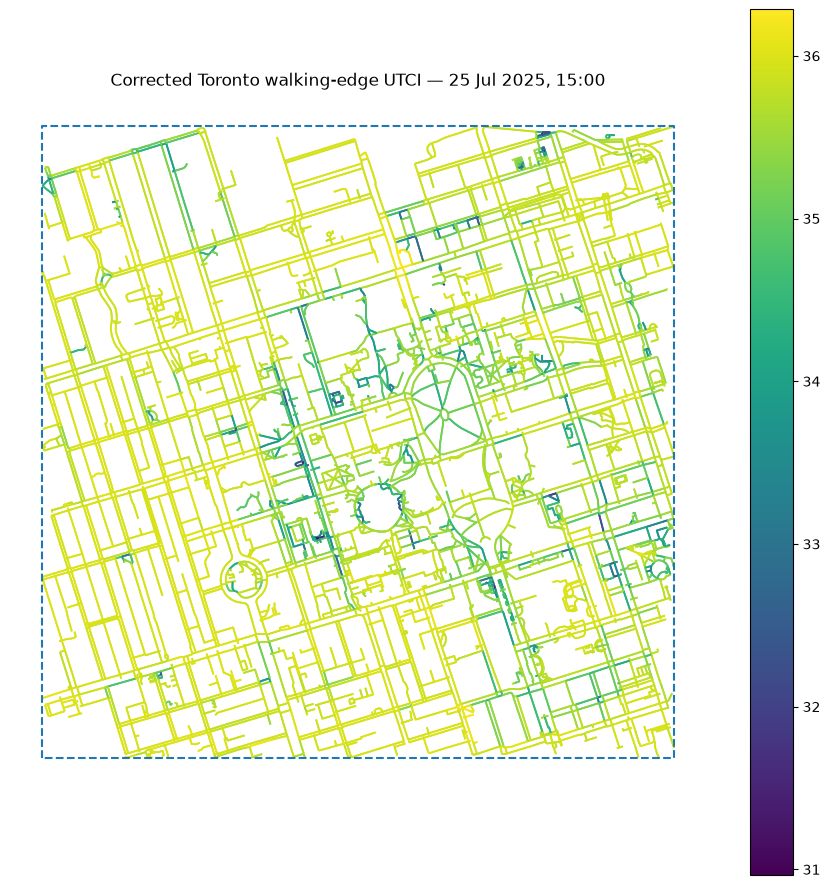

In [26]:
fig, ax = plt.subplots(
    figsize=(9, 9)
)

final_edges.plot(
    ax=ax,
    column="utci_1500",
    linewidth=1.3,
    legend=True,
)

thermal_extent.boundary.plot(
    ax=ax,
    linewidth=1.5,
    linestyle="--",
)

ax.set_title(
    "Corrected Toronto walking-edge UTCI — 25 Jul 2025, 15:00"
)

ax.set_axis_off()

plt.tight_layout()
plt.show()

## 26. Visualize the thermal generalized-cost ratio

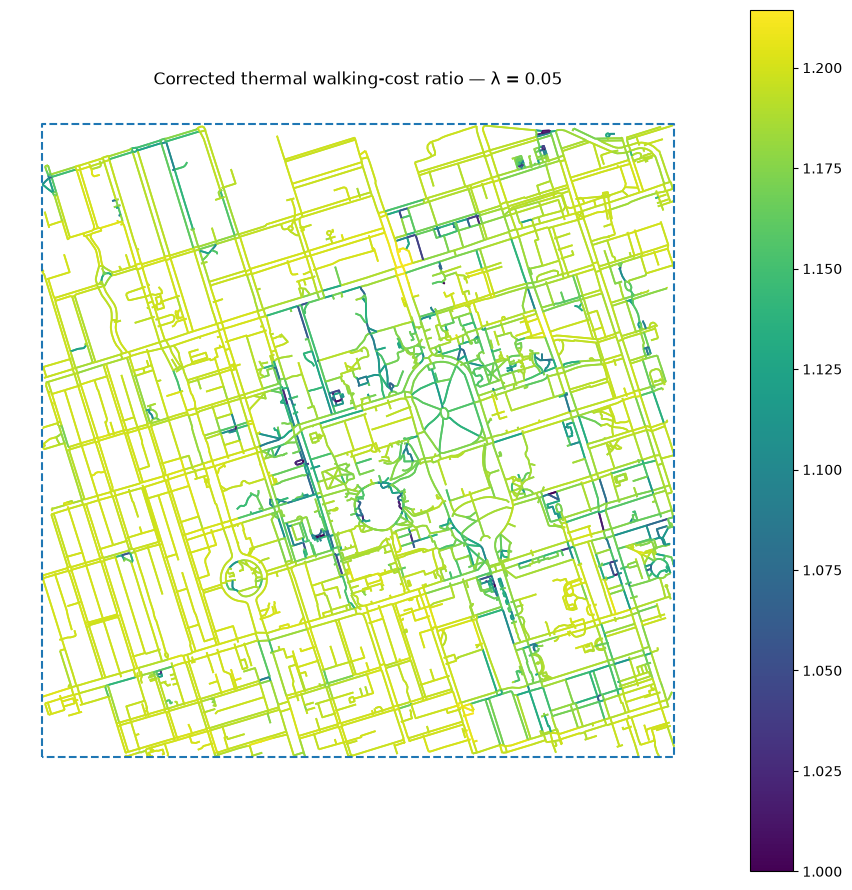

In [27]:
fig, ax = plt.subplots(
    figsize=(9, 9)
)

final_edges.plot(
    ax=ax,
    column="cost_ratio",
    linewidth=1.3,
    legend=True,
)

thermal_extent.boundary.plot(
    ax=ax,
    linewidth=1.5,
    linestyle="--",
)

ax.set_title(
    "Corrected thermal walking-cost ratio — λ = 0.05"
)

ax.set_axis_off()

plt.tight_layout()
plt.show()

## 27. λ sensitivity diagnostics

In [28]:
LAMBDA_VALUES = [
    0.00,
    0.01,
    0.025,
    0.05,
    0.075,
    0.10,
]

sensitivity_rows = []

heat_excess_series = (
    final_edges[
        "heat_excess"
    ]
)

for lam in LAMBDA_VALUES:

    ratios = (
        1.0
        + lam
        * heat_excess_series
    )

    sensitivity_rows.append(
        {
            "lambda": lam,
            "mean_cost_ratio": float(
                ratios.mean()
            ),
            "median_cost_ratio": float(
                ratios.median()
            ),
            "sd_cost_ratio": float(
                ratios.std()
            ),
            "min_cost_ratio": float(
                ratios.min()
            ),
            "max_cost_ratio": float(
                ratios.max()
            ),
        }
    )

sensitivity_df = pd.DataFrame(
    sensitivity_rows
)

display(
    sensitivity_df
)

,lambda,mean_cost_ratio,median_cost_ratio,sd_cost_ratio,min_cost_ratio,max_cost_ratio
0,0.000,1.000000,1.000000,0.000000,1.0,1.000000
1,0.010,1.035780,1.037910,0.006077,1.0,1.042872
2,0.025,1.089451,1.094774,0.015193,1.0,1.107181
3,0.050,1.178902,1.189548,0.030387,1.0,1.214362
4,0.075,1.268353,1.284322,0.045580,1.0,1.321543
5,0.100,1.357805,1.379096,0.060773,1.0,1.428724


## 28. Save corrected diagnostics

In [29]:
diagnostics_dir = (
    TORONTO_OUTPUTS
    / "thermal_network"
)

diagnostics_dir.mkdir(
    parents=True,
    exist_ok=True,
)

final_edges[
    [
        "length",
        "walk_time_s",
        "utci_1500",
        "heat_excess",
        "thermal_cost_s",
        "cost_ratio",
        "utci_sample_n",
        "geometry",
    ]
].to_file(
    diagnostics_dir
    / "toronto_uoft_thermal_edges_corrected.gpkg",
    driver="GPKG",
)

sensitivity_df.to_csv(
    diagnostics_dir
    / "thermal_cost_sensitivity_corrected.csv",
    index=False,
)

stress_table.to_csv(
    diagnostics_dir
    / "thermal_stress_shares_corrected.csv",
    index=False,
)

print(
    "Saved corrected diagnostics to:",
    diagnostics_dir,
)

Saved corrected diagnostics to: /scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/toronto/thermal_network


## 29. Save the corrected thermal graph

In [30]:
thermal_graph_path = (
    THERMAL_NETWORK_DIR
    / "toronto_uoft_walk_thermal.graphml"
)

ox.save_graphml(
    G_main,
    thermal_graph_path,
)

print(
    "Saved corrected thermal graph:"
)

print(
    thermal_graph_path
)

Saved corrected thermal graph:
/scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/interim/thermal_network/toronto_uoft_walk_thermal.graphml


## 30. Final corrected network summary

In [31]:
print(
    "Final nodes:",
    G_main.number_of_nodes(),
)

print(
    "Final edges:",
    G_main.number_of_edges(),
)

print()

print(
    "Raster UTCI range:",
    round(
        raster_min,
        3,
    ),
    "to",
    round(
        raster_max,
        3,
    ),
    "°C",
)

print(
    "Edge UTCI range:",
    round(
        float(
            final_edges[
                "utci_1500"
            ].min()
        ),
        3,
    ),
    "to",
    round(
        float(
            final_edges[
                "utci_1500"
            ].max()
        ),
        3,
    ),
    "°C",
)

print(
    "Mean edge UTCI:",
    round(
        float(
            final_edges[
                "utci_1500"
            ].mean()
        ),
        3,
    ),
    "°C",
)

print(
    "Edge UTCI SD:",
    round(
        float(
            final_edges[
                "utci_1500"
            ].std()
        ),
        3,
    ),
    "°C",
)

share_length_above_32 = float(
    final_edges.loc[
        final_edges[
            "utci_1500"
        ] > 32,
        "length",
    ].sum()
    / final_edges[
        "length"
    ].sum()
)

print(
    "Share network length >32°C:",
    round(
        share_length_above_32,
        4,
    ),
)

print(
    "Mean λ=.05 cost ratio:",
    round(
        float(
            final_edges[
                "cost_ratio"
            ].mean()
        ),
        3,
    ),
)

print(
    "Cost-ratio SD:",
    round(
        float(
            final_edges[
                "cost_ratio"
            ].std()
        ),
        3,
    ),
)

Final nodes: 3886
Final edges: 10556

Raster UTCI range: 29.449 to 36.364 °C
Edge UTCI range: 30.966 to 36.287 °C
Mean edge UTCI: 35.577 °C
Edge UTCI SD: 0.616 °C
Share network length >32°C: 0.9995
Mean λ=.05 cost ratio: 1.179
Cost-ratio SD: 0.03


## Interpretation and next step

This corrected notebook should be treated as the authoritative Toronto thermal
network stage.

Before moving to accessibility, check:

- edge UTCI minimum is not below the raster minimum;
- edge UTCI maximum is not above the raster maximum;
- no suspicious boundary-driven values remain;
- edge UTCI SD and cost-ratio SD are plausible;
- the share of network length above 32°C is understood.

If nearly all edges still exceed 32°C after the sampling correction, that is a
**scientific formulation issue**, not a geospatial bug.

In that case, the next decision is whether to retain the Sevilla-style absolute
32°C threshold for comparability or introduce an alternative impedance
formulation that better preserves relative spatial thermal contrast.

Only after this diagnostic check should we proceed to:

**`07_toronto_heat_conditioned_accessibility.ipynb`**